# Встреча 1. Стоит ли тестировать: практика

> **Время:** 55 минут · **Опирается на:** `theory.ipynb` · **Данные:** `../data/checkout_ab.csv`, `../data/portfolio_tests.csv`

**Легенда.** Команда сделала новую страницу чекаута. Владелец продукта спрашивает: «Тестируем или раскатываем сразу? И если тестируем, то сколько и с каким порогом?» Сплит уже решён: на новый чекаут пойдёт 20% трафика. От вас — вердикт с числами: $\alpha$, размер выборки, длительность и решение «тестируем / нет». Вердикт — вход встречи 2, где по нему пишется дизайн-док.

| № | Задание | Минут |
| :---: | --- | :---: |
| 1 | Точка безубыточности из данных | 10 |
| 2 | Вероятность внедрения при сплите 80/20 | 15 |
| 3 | Сетка $\alpha \times n$: оптимум по прибыли и по RR | 15 |
| 4 | Вердикт: длительность в неделях и «тестируем / нет» | 15 |

Формат: задание → ячейка `# ВАШ КОД` → свёрнутое решение → ячейка «Проверка» с `assert`.

* **Свой код проверяйте так:** запустите свою ячейку, затем сразу «Проверку», пропустив ячейку решения.
* **Решение перезаписывает ваши переменные и функции.** Поэтому не нажимайте Run All, если проверяете своё: он выполнит решения поверх вашего кода. На незаполненной заглушке Run All остановится с `NotImplementedError`.
* **Застряли больше 5 минут** — запустите решение: дальше ноутбук опирается на его переменные.

## 0. Подготовка

In [1]:
from dataclasses import dataclass, replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import TwoSlopeNorm
from matplotlib.ticker import FuncFormatter
from scipy.stats import norm

try:  # слайдеры необязательны: без ipywidgets ноутбук исполняется целиком
    from ipywidgets import FloatSlider, IntSlider, interact
except ImportError:
    interact = None

sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3

BLUE, RED, GREEN, GRAY, ORANGE = '#4C72B0', '#C44E52', '#55A868', '#7F7F7F', '#DD8452'
DATA = Path('../data/checkout_ab.csv')


def spaced(value: float) -> str:
    """Форматирует число с пробелами между разрядами."""
    return f'{value:,.0f}'.replace(',', ' ')

### Модель кейса

Готовые функции из теории. `BusinessCase` хранит параметры, `evaluate_design` считает ожидаемые выгоды, затраты, прибыль `net` и отношение `rr` для дизайна $(n_B, \alpha)$ по правилу:

* во время теста вариант B видят 20% пользователей;
* внедряем, если оценка разницы выше $\delta_{BE} + z_{1-\alpha} \cdot SE$;
* после внедрения 4 недели смотрим на дашборд: падение ниже $-1.5\%$ видно, такой вариант откатываем (потери за 4 недели + 5 млн ₽ отката); остальные работают до конца горизонта.

В ячейке ниже уже есть:

* `effect_grid`, `density` — сетка эффектов и плотность ожиданий $N(0,\ 1.5\%)$;
* `alpha_grid`, `n_grid` — оси сетки дизайнов;
* `evaluate_design(case, effect_grid, density, n_b, alpha, break_even=None)` → словарь с `net`, `rr`, `probability`;
* `ship_without_test(case, effect_grid, density)` → прибыль раскатки без теста;
* `plot_design_maps(grid, marks=None)` — тепловые карты.

Объект `case` вы соберёте в задании 1.

Функцию `implementation_probability` вы напишете в задании 2. Пока в ячейке стоит готовая версия, чтобы `evaluate_design` работала.

In [2]:
@dataclass
class BusinessCase:
    """Параметры кейса «новый чекаут». Суммы в рублях, эффекты — относительные."""
    baseline_cr: float = 0.70              # конверсия чекаута в группе A
    daily_users: int = 7_500               # пользователей в день доходят до чекаута
    share_b: float = 0.20                  # доля трафика на новый вариант
    weekly_revenue: float = 137_000_000    # ARPU группы A ≈ 2 605 ₽ × 52 500 пользователей в неделю
    fixed_test_cost: float = 3_000_000     # подготовка и проведение теста
    implementation_cost: float = 10_000_000  # раскатка на 100% трафика
    rollback_cost: float = 5_000_000       # откат на старый чекаут
    monthly_maintenance: float = 1_000_000   # поддержка нового чекаута, пока он работает
    horizon_months: float = 12             # горизонт от старта теста
    monitoring_weeks: float = 4            # сколько недель после раскатки смотрим на дашборд
    rollback_threshold: float = -0.015     # падение, которое дашборд замечает без контроля

    @property
    def weekly_users(self) -> float:
        return self.daily_users * 7

    @property
    def horizon_weeks(self) -> float:
        return self.horizon_months * 52 / 12

    @property
    def weekly_maintenance(self) -> float:
        return self.monthly_maintenance * 12 / 52

    @property
    def maintenance_cost(self) -> float:
        return self.monthly_maintenance * self.horizon_months

    @property
    def break_even(self) -> float:
        """Эффект, при котором выручка за горизонт покрывает тест, внедрение и поддержку."""
        costs = self.fixed_test_cost + self.implementation_cost + self.maintenance_cost
        return costs / (self.weekly_revenue * self.horizon_weeks)

    @property
    def break_even_sunk(self) -> float:
        """Та же точка без затрат на тест: к моменту решения они уже потрачены."""
        costs = self.implementation_cost + self.maintenance_cost
        return costs / (self.weekly_revenue * self.horizon_weeks)

    def test_weeks(self, n_b):
        """Длительность теста: группа B набирает n_b пользователей при доле share_b."""
        return np.asarray(n_b, dtype=float) / (self.share_b * self.weekly_users)


def implementation_probability(p_control, relative_effect, break_even_effect, n_b, alpha=0.05, share_b=0.2):
    """Вероятность внедрения: оценка разницы выше порога delta_BE + z_{1-alpha} * SE. Сплит share_b, n_A = n_b (1 - s) / s."""
    n_b = np.asarray(n_b, dtype=float)
    n_a = n_b * (1 - share_b) / share_b
    p_true = np.clip(p_control * (1 + relative_effect), 1e-6, 1 - 1e-6)
    delta_true = p_true - p_control
    delta_be = p_control * break_even_effect
    se = np.sqrt(p_control * (1 - p_control) / n_a + p_true * (1 - p_true) / n_b)
    return norm.sf(norm.ppf(1 - alpha) - (delta_true - delta_be) / se)


def evaluate_design(case, effect_grid, density, n_b, alpha, break_even=None):
    """
    Выгоды и затраты с поправкой на риск для дизайна (n_b, alpha).

    break_even — порог решения (по умолчанию case.break_even; 0 — «стандартная» проверка против нуля).
    n_b и alpha можно передать массивами: ось эффектов всегда последняя.
    """
    threshold = case.break_even if break_even is None else break_even
    probability = implementation_probability(case.baseline_cr, effect_grid, threshold, n_b, alpha, case.share_b)

    test_weeks = case.test_weeks(n_b)
    post_weeks = np.maximum(case.horizon_weeks - test_weeks, 0)   # длинный тест откладывает внедрение
    watch_weeks = np.minimum(case.monitoring_weeks, post_weeks)    # мониторинг после раскатки
    rest_weeks = post_weeks - watch_weeks                          # остаток горизонта
    keep = effect_grid >= case.rollback_threshold                  # падение ниже порога видно и откатывается
    live_weeks = watch_weeks + rest_weeks * keep                   # сколько недель вариант работает

    test_value = case.share_b * case.weekly_revenue * effect_grid * test_weeks   # 20% трафика во время теста
    live_value = case.weekly_revenue * effect_grid * live_weeks
    decision_costs = (case.implementation_cost + case.weekly_maintenance * live_weeks
                      + case.rollback_cost * (~keep))

    gains = (np.maximum(test_value, 0) + np.maximum(live_value, 0) * probability) * density
    losses = (np.maximum(-test_value, 0) + (np.maximum(-live_value, 0) + decision_costs) * probability) * density

    expected_gain = np.trapezoid(gains, effect_grid, axis=-1)
    expected_loss = case.fixed_test_cost + np.trapezoid(losses, effect_grid, axis=-1)
    return {
        'probability': probability,
        'gains': gains,
        'losses': losses,
        'expected_gain': expected_gain,
        'expected_loss': expected_loss,
        'rr': expected_gain / expected_loss,
        'net': expected_gain - expected_loss,
    }


def ship_without_test(case, effect_grid, density):
    """Внедрить сразу: нет затрат на тест и задержки, но мониторинг и откат те же."""
    keep = effect_grid >= case.rollback_threshold
    live_weeks = case.monitoring_weeks + (case.horizon_weeks - case.monitoring_weeks) * keep
    profit = (case.weekly_revenue * effect_grid * live_weeks - case.implementation_cost
              - case.weekly_maintenance * live_weeks - case.rollback_cost * (~keep))
    return np.trapezoid(profit * density, effect_grid)



PRIOR_MU, PRIOR_SIGMA = 0.0, 0.015
effect_grid = np.linspace(-0.12, 0.12, 2401)   # одна сетка эффектов на весь ноутбук


def prior_density(mu: float = PRIOR_MU, sigma: float = PRIOR_SIGMA) -> np.ndarray:
    """Нормальное распределение ожиданий на сетке; сетка обрезает хвосты, поэтому нормируем заново."""
    weights = norm.pdf(effect_grid, mu, sigma)
    return weights / np.trapezoid(weights, effect_grid)


density = prior_density()


alpha_grid = np.array([0.01, 0.025, 0.05, 0.075, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, 0.8])
n_grid = np.unique(np.round(np.geomspace(1_000, 300_000, 60), -2)).astype(int)   # n_B: от 0.7 дня до 200 дней


def plot_design_maps(grid: dict, marks: dict = None, title: str = None) -> None:
    """Рисует тепловые карты RR и прибыли на сетке alpha и n_B."""
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.8), sharey=True)
    panels = [(axes[0], grid['rr'], 1, 'RR', 'rr'), (axes[1], grid['net'] / 1e6, 0, 'Чистая прибыль, млн ₽', 'net')]

    for ax, values, center, label, metric in panels:
        low, high = values.min(), values.max()
        if not low < center < high:
            low, high = min(low, center - 1e-6), max(high, center + 1e-6)
        mesh = ax.pcolormesh(n_grid, np.arange(alpha_grid.size), values, cmap='RdBu', shading='nearest',
                             norm=TwoSlopeNorm(vmin=low, vcenter=center, vmax=high))
        fig.colorbar(mesh, ax=ax, label=label)
        ax.contour(n_grid, np.arange(alpha_grid.size), values, levels=[center], colors='black', linewidths=1.5)

        best_alpha, best_n, *_ = best_design(grid, metric)
        ax.scatter(best_n, np.searchsorted(alpha_grid, best_alpha), marker='*', s=340, color='#EDB120',
                   edgecolor='black', zorder=4, label=f'Оптимум: α = {best_alpha}, n_B = {spaced(best_n)}')
        for name, (mark_alpha, mark_n) in (marks or {}).items():
            ax.scatter(mark_n, np.searchsorted(alpha_grid, mark_alpha), marker='o', s=110, color='white',
                       edgecolor='black', zorder=4, label=name)
        ax.set_xscale('log')
        ax.set_xlabel('Размер группы B, n_B (логарифмическая шкала)')
        ax.legend(loc='lower left', fontsize=10)
        ax.grid(False)

    axes[0].set_yticks(np.arange(alpha_grid.size), alpha_grid)
    axes[0].set_ylabel('Уровень значимости α, односторонний')
    if title:
        fig.suptitle(title, x=0.01, ha='left')
    plt.tight_layout()
    plt.show()

## Задание 1. Точка безубыточности (10 минут)

Затраты (оценка команды): тест — 3 млн ₽, внедрение — 10 млн ₽, поддержка — 1 млн ₽ в месяц, горизонт — 12 месяцев (52 недели). Выручку и трафик возьмите из данных.

По `checkout_ab.csv` посчитайте:

1. `daily_users` — уникальных пользователей в день (уникальные `user_id` / число дней);
2. `arpu_a` — средняя выручка на пользователя группы A (дубли по `user_id` уберите: `drop_duplicates('user_id')`);
3. `weekly_revenue` — `arpu_a × 7 500 × 7`, округлённая до миллиона;
4. `break_even` — относительный эффект, при котором выручка за горизонт покрывает тест, внедрение и поддержку;
5. `break_even_pp` — то же в процентных пунктах конверсии при $p_A = 0.70$.

In [3]:
df = pd.read_csv(DATA)
df.head()

,user_id,date,group,converted,revenue,checkout_time_sec,payment_error,orders_prev28,revenue_prev28
0,7480367,2026-09-20,A,1,997.12,261.9,0,2,3817.54
1,9280410,2026-09-12,A,1,23649.07,55.2,0,7,109549.40
2,5231080,2026-09-16,B,1,1719.31,17.5,0,1,2166.69
3,9684298,2026-09-13,A,1,2037.39,123.9,0,2,3051.12
4,1961867,2026-09-12,A,1,1761.46,45.4,0,2,2938.46


In [4]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [5]:
# @title Решение (нажмите, чтобы раскрыть)
users = df.drop_duplicates('user_id')
daily_users = users['user_id'].nunique() / users['date'].nunique()
arpu_a = users.loc[users['group'] == 'A', 'revenue'].mean()
weekly_revenue = round(arpu_a * 7_500 * 7, -6)

fixed_costs = 3_000_000 + 10_000_000 + 1_000_000 * 12
break_even = fixed_costs / (weekly_revenue * 52)
break_even_pp = break_even * 0.70 * 100

print(f"Пользователей в день: {daily_users:,.0f}; ARPU A: {arpu_a:,.0f} ₽; выручка за неделю: {weekly_revenue:,.0f} ₽".replace(',', ' '))
print(f"Точка безубыточности: {break_even:.3%} относительных = {break_even_pp:.2f} п.п.")

Пользователей в день: 7 501; ARPU A: 2 605 ₽; выручка за неделю: 137 000 000 ₽
Точка безубыточности: 0.351% относительных = 0.25 п.п.


**Проверка.** Трафик близок к заявленным 7 500 в день, выручка — 137 млн ₽ в неделю, точка безубыточности — 0.35%.

In [6]:
# Проверка
assert abs(daily_users - 7_500) < 50, 'Трафик должен быть около 7 500 в день: делите уникальных пользователей на число дней'
assert abs(arpu_a - 2_605) < 10, 'ARPU группы A ≈ 2 605 ₽: среднее revenue по всем пользователям A, включая тех, у кого 0'
assert weekly_revenue == 137_000_000
assert abs(break_even - 0.003509) < 1e-5, 'BE = (тест + внедрение + поддержка за год) / (выручка за неделю × 52)'
assert abs(break_even_pp - 0.2457) < 0.001
print('Задание 1 принято')

Задание 1 принято


Соберём параметры кейса: дальше все задания работают с `case`.

In [7]:
case = BusinessCase(daily_users=7_500, weekly_revenue=weekly_revenue)
print(f"BE модели: {case.break_even:.3%}")

BE модели: 0.351%


**Вопрос.** Точка безубыточности — 0.25 п.п. Это много или мало для теста на две недели? Сколько это заказов в неделю?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Мало. За две недели группа B набирает 21 тыс. пользователей, A — 84 тыс.

Стандартная ошибка разницы конверсий — $\sqrt{0.21/84\,000 + 0.21/21\,000} \approx 0.35$ п.п. Это больше самой точки безубыточности.

Значит, тест не отличит надёжно «чуть выше BE» от «чуть ниже». Это нормально: его задача — отсечь заметно худшие варианты и пропустить заметно лучшие.

В заказах: 0.25 п.п. от 52 500 пользователей в неделю — около 130 дополнительных заказов. В деньгах — 0.48 млн ₽ выручки в неделю (0.35% от 137 млн). За 52 недели набегает ровно 25 млн ₽ — столько стоят тест, внедрение и год поддержки.

</details>

## Задание 2. Вероятность внедрения при сплите 80/20 (15 минут)

Правило внедрения: оценка разницы конверсий $\hat\delta = \hat p_B - \hat p_A$ выше порога

$$
\hat\delta > \delta_{BE} + z_{1-\alpha} \cdot SE, \qquad \delta_{BE} = p_A\,\theta_{BE}, \qquad SE = \sqrt{\frac{p_A(1-p_A)}{n_A} + \frac{p_B(1-p_B)}{n_B}},
$$

где $p_B = p_A(1 + \theta)$, а при доле B $s$ контрольная группа $n_A = n_B(1-s)/s$. Оценка $\hat\delta$ примерно нормальна со средним $p_B - p_A$ и стандартной ошибкой $SE$.

Напишите `implementation_probability(p_control, relative_effect, break_even_effect, n_b, alpha, share_b)` — вероятность внедрения при истинном относительном эффекте `relative_effect`. Функция должна работать с массивами (`relative_effect`, `n_b` и `alpha` — numpy-массивы, которые транслируются друг на друга).

In [8]:
def implementation_probability(p_control, relative_effect, break_even_effect, n_b, alpha=0.05, share_b=0.2):
    # ВАШ КОД
    raise NotImplementedError

In [9]:
# @title Решение (нажмите, чтобы раскрыть)
def implementation_probability(p_control, relative_effect, break_even_effect, n_b, alpha=0.05, share_b=0.2):
    n_b = np.asarray(n_b, dtype=float)
    n_a = n_b * (1 - share_b) / share_b
    p_true = np.clip(p_control * (1 + relative_effect), 1e-6, 1 - 1e-6)
    delta_true = p_true - p_control
    delta_be = p_control * break_even_effect
    se = np.sqrt(p_control * (1 - p_control) / n_a + p_true * (1 - p_true) / n_b)
    return norm.sf(norm.ppf(1 - alpha) - (delta_true - delta_be) / se)

**Проверка.** Три свойства: (1) при $\theta = \theta_{BE}$ вероятность равна $\alpha$ при любом $n$; (2) она совпадает с частотой внедрения в симуляции биномиальных конверсий; (3) сплит 80/20 даёт ту же вероятность, что и 50/50 с тем же $SE$, то есть в $1.56$ раза больше пользователей.

In [10]:
# Проверка
p_a = case.baseline_cr
for n_b in [1_000, 21_000, 200_000]:
    for alpha in [0.025, 0.3, 0.5]:
        assert abs(implementation_probability(p_a, case.break_even, case.break_even, n_b, alpha) - alpha) < 1e-9

rng = np.random.default_rng(1)
n_b, alpha, theta = 21_000, 0.3, 0.01
n_a = 4 * n_b
x_a = rng.binomial(n_a, p_a, 200_000) / n_a
x_b = rng.binomial(n_b, p_a * (1 + theta), 200_000) / n_b
se_hat = np.sqrt(x_a * (1 - x_a) / n_a + x_b * (1 - x_b) / n_b)
simulated = np.mean(x_b - x_a > p_a * case.break_even + norm.ppf(1 - alpha) * se_hat)
formula = implementation_probability(p_a, theta, case.break_even, n_b, alpha)
print(f"θ = +1%, n_B = 21 000, α = 0.3: формула {formula:.4f}, симуляция {simulated:.4f}")
assert abs(formula - simulated) < 0.005, 'Не сходится с симуляцией: проверьте n_A = 4 n_B и SE'

# 80/20 с n_B против 50/50 с тем же SE: при равных дисперсиях N_50/50 = N_80/20 / 1.5625
p8020 = implementation_probability(p_a, 0.01, 0.0, 20_000, 0.025, 0.2)
p5050 = implementation_probability(p_a, 0.01, 0.0, 100_000 / 1.5625 / 2, 0.025, 0.5)
assert abs(p8020 - p5050) < 0.01
assert implementation_probability(p_a, np.array([-0.01, 0.01]), case.break_even, np.array([[2_000], [50_000]]), 0.05).shape == (2, 2)
print('Задание 2 принято')

θ = +1%, n_B = 21 000, α = 0.3: формула 0.7787, симуляция 0.7778
Задание 2 принято


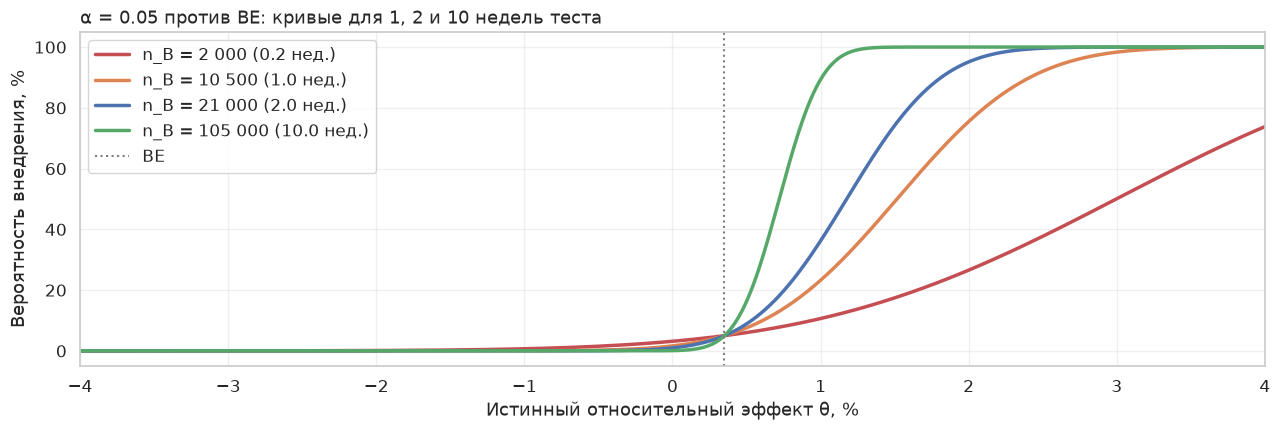

In [11]:
fig, ax = plt.subplots(figsize=(13, 4.5))
for n_b, color in [(2_000, RED), (10_500, ORANGE), (21_000, BLUE), (105_000, GREEN)]:
    ax.plot(effect_grid * 100, implementation_probability(p_a, effect_grid, case.break_even, n_b, 0.05) * 100,
            color=color, linewidth=2.5, label=f'n_B = {spaced(n_b)} ({case.test_weeks(n_b):.1f} нед.)')
ax.axvline(case.break_even * 100, color=GRAY, linestyle=':', label='BE')
ax.set_xlim(-4, 4)
ax.set_xlabel('Истинный относительный эффект θ, %')
ax.set_ylabel('Вероятность внедрения, %')
ax.set_title('α = 0.05 против BE: кривые для 1, 2 и 10 недель теста', loc='left')
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

**Вопрос.** Почему все кривые проходят через одну точку? Что меняется, если отдать B не 20%, а 50% трафика при той же длительности?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

При $\theta = \theta_{BE}$ оценка $\hat\delta$ в среднем равна $\delta_{BE}$. Поэтому правило «выше $\delta_{BE} + z_{1-\alpha} SE$» срабатывает ровно с вероятностью $\alpha$ при любом $SE$. Выборка меняет только крутизну кривой вокруг этой точки.

При сплите 50/50 за то же время $n_B$ вырастает в 2.5 раза, а $n_A$ падает с $4n_B$ до $n_B$. Дисперсия разницы пропорциональна $1/n_A + 1/n_B$: при общем трафике $N$ это $6.25/N$ для 80/20 и $4/N$ для 50/50.

Итог: кривые станут круче, как при выборке в 1.56 раза больше. Цена — сырой вариант видит больше пользователей, и если он плох, во время теста теряем больше денег.

</details>

## Задание 3. Сетка $\alpha \times n$ (15 минут)

Посчитайте `evaluate_design` сразу для всей сетки `alpha_grid × n_grid` (подсказка: `n_grid[None, :, None]`, `alpha_grid[:, None, None]`; ось эффектов — последняя). Найдите два оптимума и сохраните их в словари:

* `best_net = {'alpha': ..., 'n_b': ..., 'net': ..., 'rr': ...}` — максимум ожидаемой прибыли;
* `best_rr = {...}` — максимум отношения выгоды к риску.

Убедитесь, что оптимум по прибыли не лежит на краю сетки.

In [12]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [13]:
# @title Решение (нажмите, чтобы раскрыть)
grid = evaluate_design(case, effect_grid, density, n_grid[None, :, None], alpha_grid[:, None, None])


def pick(metric: str) -> dict:
    row, column = np.unravel_index(np.argmax(grid[metric]), grid[metric].shape)
    return {'alpha': float(alpha_grid[row]), 'n_b': int(n_grid[column]),
            'net': float(grid['net'][row, column]), 'rr': float(grid['rr'][row, column])}


best_net, best_rr = pick('net'), pick('rr')
for name, best in [('Максимум прибыли', best_net), ('Максимум RR', best_rr)]:
    print(f"{name}: α = {best['alpha']}, n_B = {spaced(best['n_b'])} ({case.test_weeks(best['n_b']) * 7:.1f} дн.), "
          f"прибыль {best['net'] / 1e6:.2f} млн ₽, RR = {best['rr']:.2f}")

Максимум прибыли: α = 0.5, n_B = 24 300 (16.2 дн.), прибыль 26.09 млн ₽, RR = 3.09
Максимум RR: α = 0.05, n_B = 18 200 (12.1 дн.), прибыль 20.99 млн ₽, RR = 3.62


**Проверка.** Сверяем с перебором «в лоб»: по одному дизайну за вызов.

In [14]:
# Проверка
brute = np.array([[evaluate_design(case, effect_grid, density, n_b, alpha)['net'] for n_b in n_grid] for alpha in alpha_grid])
row, column = np.unravel_index(np.argmax(brute), brute.shape)
assert (best_net['alpha'], best_net['n_b']) == (alpha_grid[row], n_grid[column])
assert abs(best_net['net'] - brute.max()) < 1
assert 0 < column < n_grid.size - 1 and 0 < row < alpha_grid.size - 1, 'Оптимум на краю сетки — расширьте её'
assert best_net['alpha'] == 0.5 and best_net['n_b'] == 24_300 and abs(best_net['net'] / 1e6 - 26.09) < 0.05
assert best_rr['alpha'] == 0.05 and best_rr['n_b'] == 18_200 and abs(best_rr['rr'] - 3.62) < 0.01
print('Задание 3 принято')

Задание 3 принято


Дальше сетку считаем готовыми функциями: `design_grid(case, weights, break_even)` — то же, что вы написали, и `best_design(grid, metric)` → (α, n_B, RR, прибыль).

In [15]:
def design_grid(case: BusinessCase, weights: np.ndarray = None, break_even: float = None) -> dict:
    """Считает RR и прибыль для всех сочетаний alpha и n_B."""
    weights = density if weights is None else weights
    return evaluate_design(case, effect_grid, weights, n_grid[None, :, None], alpha_grid[:, None, None], break_even)


def best_design(grid: dict, metric: str) -> tuple:
    """Находит alpha и n_B с максимальным значением метрики."""
    row, column = np.unravel_index(np.argmax(grid[metric]), grid[metric].shape)
    return alpha_grid[row], n_grid[column], grid['rr'][row, column], grid['net'][row, column]

Стандарт (α = 0.025 против нуля, MDE +1 п.п.): n_B = 20 604, прибыль 23.22 млн ₽


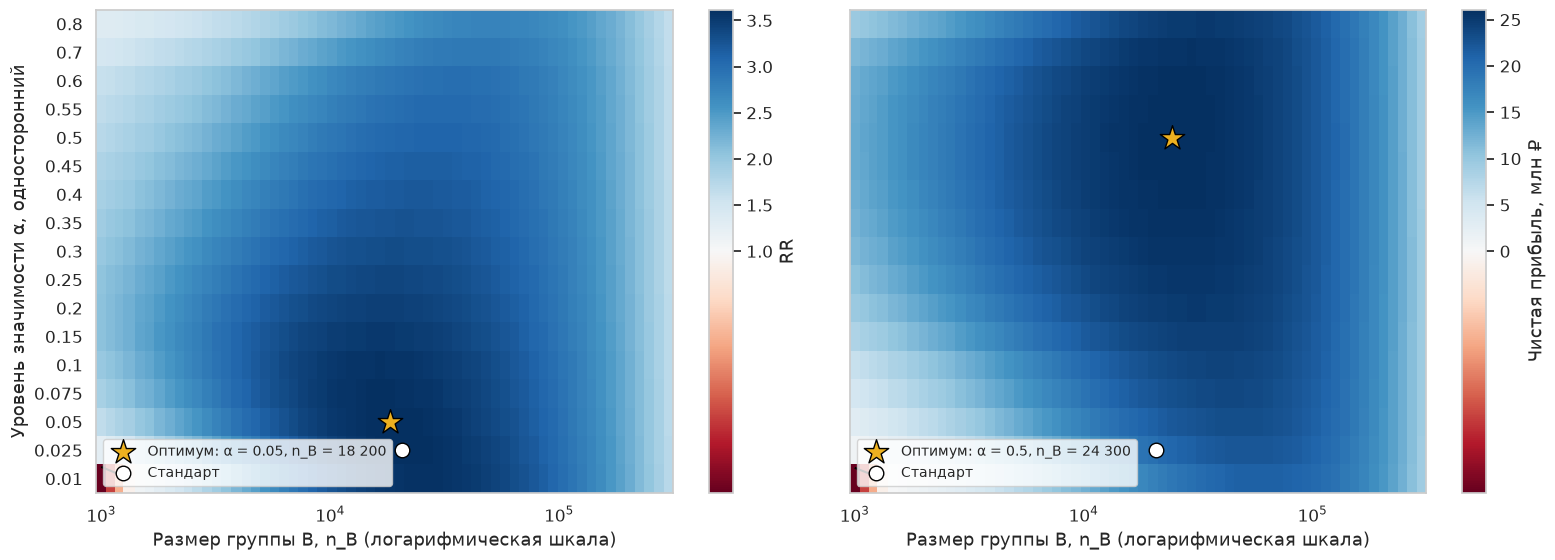

In [16]:
grid_full = design_grid(case)
p, s = case.baseline_cr, case.share_b
n_standard = int(np.ceil((norm.ppf(0.975) + norm.ppf(0.8)) ** 2 * p * (1 - p) * (1 + s / (1 - s)) / 0.01 ** 2))
standard = evaluate_design(case, effect_grid, density, n_standard, 0.025, break_even=0.0)
print(f"Стандарт (α = 0.025 против нуля, MDE +1 п.п.): n_B = {spaced(n_standard)}, прибыль {standard['net'] / 1e6:.2f} млн ₽")
plot_design_maps(grid_full, {'Стандарт': (0.025, n_standard)})

**Вопрос.** Почему максимум RR выбирает более строгий $\alpha$ и более короткий тест, чем максимум прибыли? На что смотреть, если в очереди 10 идей, а трафик один?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

RR — отношение. Его можно поднять, урезая затраты быстрее, чем выгоды: строгий $\alpha$ реже платит 10 млн ₽ за внедрение, короткий тест меньше рискует во время теста. Прибыль при этом падает на 5 млн ₽.

К тому же RR зависит от бухгалтерии. Проведите внедрение как минус в выгодах, а не как плюс в затратах: прибыль не изменится, а RR и его оптимум сдвинутся.

Если трафик дефицитен и идей много, сравнивайте **прибыль на неделю теста**: 11.3 млн ₽ у максимума прибыли и 12.1 млн ₽ у максимума RR. Короткий тест со строгим порогом освобождает трафик для следующей идеи.

Оговорка: этот критерий честен, только пока в очереди есть сопоставимые идеи.

</details>

## Задание 4. Вердикт (15 минут)

Оптимум по прибыли — $n_B = 24\,300$, но тест нельзя остановить посреди недели: поведение в будни и выходные различается. Соберите вердикт:

1. переведите оптимальный $n_B$ в дни при доступном трафике: `days = n_B / (share_b × daily_users)`;
2. возьмите два кандидата — целое число недель вниз и вверх (не меньше 1), для каждого $n_B = \text{недель} \times 7 \times 0.2 \times 7\,500$ подберите лучший $\alpha$ на `alpha_grid` и посчитайте прибыль;
3. выберите кандидата с большей прибылью и сравните его с альтернативами без теста: «ничего не делать» (0) и «внедрить сразу» (`ship_without_test`);
4. решение «тестируем», если тест прибыльнее обеих альтернатив, иначе «не тестируем».

Сохраните словарь `VERDICT = {"alpha": ..., "break_even_pp": ..., "n_b": ..., "n_total": ..., "days": ..., "decision": ...}` и прибыль выбранного дизайна в `verdict_net`. Здесь `break_even_pp` — порог решения в п.п., против которого задан $\alpha$; `n_total` — обе группы; `days` — целое число дней.

In [17]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [18]:
# @title Решение (нажмите, чтобы раскрыть)
optimum_days = best_net['n_b'] / (case.share_b * case.daily_users)
weeks_candidates = sorted({max(1, int(np.floor(optimum_days / 7))), int(np.ceil(optimum_days / 7))})

candidates = []
for weeks in weeks_candidates:
    n_b = int(weeks * 7 * case.share_b * case.daily_users)
    result = evaluate_design(case, effect_grid, density, n_b, alpha_grid[:, None])
    i = int(np.argmax(result['net']))
    candidates.append({'weeks': weeks, 'alpha': float(alpha_grid[i]), 'n_b': n_b, 'net': float(result['net'][i])})
    print(f"{weeks} нед.: n_B = {spaced(n_b)}, лучший α = {alpha_grid[i]}, прибыль {result['net'][i] / 1e6:.2f} млн ₽")

chosen = max(candidates, key=lambda row: row['net'])
no_test = ship_without_test(case, effect_grid, density)
verdict_net = chosen['net']
decision = 'тестируем' if verdict_net > max(0.0, no_test) else 'не тестируем'
print(f"Оптимум {optimum_days:.1f} дн.; внедрить без теста: {no_test / 1e6:.2f} млн ₽; ничего не делать: 0")

VERDICT = {
    'alpha': chosen['alpha'],
    'break_even_pp': float(round(case.break_even * case.baseline_cr * 100, 3)),   # H0: p_B − p_A ≤ break_even_pp п.п., α одностороннее
    'n_b': chosen['n_b'],
    'n_total': int(round(chosen['n_b'] / case.share_b)),
    'days': chosen['weeks'] * 7,
    'decision': decision,
}

2 нед.: n_B = 21 000, лучший α = 0.5, прибыль 26.03 млн ₽
3 нед.: n_B = 31 500, лучший α = 0.5, прибыль 26.01 млн ₽
Оптимум 16.2 дн.; внедрить без теста: 2.75 млн ₽; ничего не делать: 0


**Проверка.** Две недели выигрывают у трёх на десятки тысяч рублей: плато прибыли широкое, и округление до недель почти ничего не стоит.

In [19]:
# Проверка
assert set(VERDICT) == {'alpha', 'break_even_pp', 'n_b', 'n_total', 'days', 'decision'}
assert abs(VERDICT['break_even_pp'] - 0.246) < 1e-3, 'Порог в п.п.: break_even × 0.70 × 100'
assert VERDICT['decision'] == 'тестируем'
assert VERDICT['days'] % 7 == 0, 'Длительность — целое число недель'
assert VERDICT['n_b'] == 21_000 and VERDICT['n_total'] == 105_000 and VERDICT['days'] == 14
assert VERDICT['alpha'] == 0.5
assert abs(verdict_net - best_net['net']) / best_net['net'] < 0.01, 'Округление до недель должно стоить меньше 1% прибыли'
print('Задание 4 принято')

Задание 4 принято


**Вопрос.** Вердикт — $\alpha = 0.5$ против точки безубыточности. Как сформулировать правило решения владельцу продукта так, чтобы он не услышал «подбрасываем монетку»?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

«Через две недели внедряем новый чекаут, если его конверсия в тесте выше старой хотя бы на 0.25 п.п. Это точка, где он окупает тест, внедрение и год поддержки».

Одностороннее $\alpha = 0.5$ против BE и есть правило «оценка выше порога». Вероятность внедрить вариант растёт с его эффектом, а не равна 50%.

Цену правила тоже называем числами (проверьте через `implementation_probability`):

* вариант на 1% хуже контроля внедрится с вероятностью 0.4%;
* вариант без эффекта — с вероятностью 24%;
* вариант на 1% лучше — с вероятностью 90%.

Крупные провалы, если всё же проскочат, ловит мониторинг после раскатки.

</details>

## Итог: вердикт для встречи 2

Вердикт — вход встречи 2: по нему считаем MDE, проверяем длительность и пишем дизайн-док. Совпадение с датасетом не случайно: `checkout_ab.csv` — это ровно 14 дней теста по такому плану.

Во встречу 2 передаём не только $\alpha$, но и порог: $\alpha = 0.5$ без `break_even_pp` теряет смысл.

In [20]:
print(f"Прибыль выбранного дизайна: {verdict_net / 1e6:.2f} млн ₽; без теста: {no_test / 1e6:.2f} млн ₽")
z = norm.ppf(1 - VERDICT['alpha'])
se_pp = 100 * np.sqrt(case.baseline_cr * (1 - case.baseline_cr) * (1 / (VERDICT['n_total'] - VERDICT['n_b']) + 1 / VERDICT['n_b']))
boundary = VERDICT['break_even_pp'] + z * se_pp
print(f"Правило: внедряем, если p̂_B − p̂_A > {VERDICT['break_even_pp']:.2f} п.п. + {z:.2f} · SE = {boundary:.2f} п.п. (SE ≈ {se_pp:.2f} п.п.)")
print(f"В терминах теста против нуля это одностороннее α ≈ {norm.sf(boundary / se_pp):.2f}; мощность 80% — для разницы ≈ {boundary + norm.ppf(0.8) * se_pp:.2f} п.п.")
VERDICT

Прибыль выбранного дизайна: 26.03 млн ₽; без теста: 2.75 млн ₽
Правило: внедряем, если p̂_B − p̂_A > 0.25 п.п. + 0.00 · SE = 0.25 п.п. (SE ≈ 0.35 п.п.)
В терминах теста против нуля это одностороннее α ≈ 0.24; мощность 80% — для разницы ≈ 0.54 п.п.


{'alpha': 0.5,
 'break_even_pp': 0.246,
 'n_b': 21000,
 'n_total': 105000,
 'days': 14,
 'decision': 'тестируем'}

## Дополнительные задания

### Д1. Ожидания по истории тестов

В теории $\sigma = 1.5\%$ задана рассуждением. Оценим разброс эффектов по портфелю прошлых тестов `portfolio_tests.csv` (эффект и SE — в п.п. конверсии).

Наблюдаемый эффект теста — это истинный эффект плюс шум: $\hat\theta_i = \theta_i + \varepsilon_i$, $\varepsilon_i \sim N(0, SE_i^2)$. Поэтому разброс наблюдаемых эффектов завышает разброс истинных. Оценка методом моментов:

$$
\hat\tau^2 = \max\Big(0,\ \operatorname{Var}(\hat\theta_i) - \overline{SE_i^2}\Big).
$$

Переведите эффекты и SE в относительные (делим на `base_rate`), посчитайте `tau_all` по всем тестам и `tau_wo_outlier` без самого большого эффекта.

In [21]:
portfolio = pd.read_csv('../data/portfolio_tests.csv')
portfolio

,test_id,name,metric,n,base_rate,effect,se,ci_low,ci_high,p_value
0,HD-101,Блок рекомендаций на главной,"конверсия, п.п.",52000,0.050,0.334,0.135,0.069,0.599,0.0135
1,PRM-104,Промо-баннер в выдаче,"конверсия, п.п.",38000,0.048,0.276,0.155,-0.028,0.580,0.0751
2,CHK-203,Новый чекаут v2,"конверсия, п.п.",78000,0.052,0.187,0.112,-0.033,0.408,0.0954
3,PUSH-307,Другое время push-рассылки,"конверсия, п.п.",64000,0.050,0.063,0.122,-0.176,0.302,0.6064
4,ONB-112,Мобильный онбординг,"конверсия, п.п.",30000,0.047,1.210,0.173,0.871,1.549,0.0000
5,FILT-408,Фильтр по цене в поиске,"конверсия, п.п.",44000,0.051,-0.227,0.148,-0.518,0.064,0.1257


In [22]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [23]:
# @title Решение (нажмите, чтобы раскрыть)
relative = portfolio['effect'] / 100 / portfolio['base_rate']
relative_se = portfolio['se'] / 100 / portfolio['base_rate']


def tau(effects, ses) -> float:
    return float(np.sqrt(max(0.0, effects.var(ddof=1) - (ses ** 2).mean())))


keep = relative < relative.max()
tau_all = tau(relative, relative_se)
tau_wo_outlier = tau(relative[keep], relative_se[keep])
print(f"Наблюдаемый разброс: {relative.std(ddof=1):.1%}; средний шум SE: {np.sqrt((relative_se ** 2).mean()):.1%}")
print(f"τ по всем тестам: {tau_all:.1%}; без выброса: {tau_wo_outlier:.1%}")

Наблюдаемый разброс: 10.3%; средний шум SE: 2.9%
τ по всем тестам: 9.8%; без выброса: 3.5%


In [24]:
# Проверка
assert abs(tau_all - 0.098) < 0.003
assert abs(tau_wo_outlier - 0.035) < 0.003
print('Д1 принято')

Д1 принято


**Вопрос.** Можно ли просто взять $\sigma = 3.5\%$ для нашего чекаута?

<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

Нет, и тут сразу три проблемы.

1. **Референтный класс.** В портфеле базовая конверсия ~5%, у нас — 70%. Относительный эффект +3.5% при базе 5% — это +0.18 п.п., при базе 70% — +2.5 п.п. Это совсем другая по силе правка. Перенос в относительных величинах завышает $\sigma$, в абсолютных — занижает.
2. **Шум и малое число тестов.** По шести тестам дисперсия оценивается очень грубо, а вычитание $\overline{SE^2}$ легко даёт ноль или отрицательное число.
3. **Выброс.** Один онбординг (+26%) утраивает оценку. Выбрасывать его тоже нельзя без причины: тяжёлые хвосты эффектов — реальность, и нормальное распределение их недооценивает.

Поэтому $\sigma$ — это суждение, подкреплённое историей, и его обязательно проверяют на чувствительность (Д2). Сжатие оценок отдельных тестов к общему среднему (shrinkage) и мета-анализ портфеля — встреча 6.

</details>

### Д2. Чувствительность вердикта

Пересчитайте оптимум по прибыли (α, $n_B$, недели, прибыль) и прибыль «внедрить без теста» для сценариев:

* $\sigma = 0.75\%$ и $\sigma = 3\%$;
* ожидания со сдвигом: $\mu = -0.5\%$ и $\mu = +0.5\%$;
* горизонт 3 месяца;
* мониторинга нет (`rollback_threshold=-1.0`: откат не случается никогда).

Что меняет вердикт «тестируем», а что — только $\alpha$ и $n$?

In [25]:
# ВАШ КОД
raise NotImplementedError

NotImplementedError: 

In [26]:
# @title Решение (нажмите, чтобы раскрыть)
scenarios = {
    'Базовый': ({}, 0.0, 0.015),
    'σ = 0.75%': ({}, 0.0, 0.0075),
    'σ = 3%': ({}, 0.0, 0.03),
    'μ = −0.5%': ({}, -0.005, 0.015),
    'μ = +0.5%': ({}, 0.005, 0.015),
    'Горизонт 3 месяца': ({'horizon_months': 3}, 0.0, 0.015),
    'Без мониторинга': ({'rollback_threshold': -1.0}, 0.0, 0.015),
}
rows = []
for name, (changes, mu, sigma) in scenarios.items():
    custom = replace(case, **changes)
    weights = prior_density(mu, sigma)
    alpha, n_b, rr, net = best_design(design_grid(custom, weights), 'net')
    no_test = ship_without_test(custom, effect_grid, weights)
    rows.append({'Сценарий': name, 'α': alpha, 'n_B': n_b, 'Недель': round(custom.test_weeks(n_b), 1),
                 'Прибыль теста, млн ₽': round(net / 1e6, 2), 'Без теста, млн ₽': round(no_test / 1e6, 2),
                 'Вердикт': 'тестируем' if net > max(0, no_test) else 'не тестируем'})
sensitivity = pd.DataFrame(rows).set_index('Сценарий')
sensitivity

,α,n_B,Недель,"Прибыль теста, млн ₽","Без теста, млн ₽",Вердикт
Сценарий,,,,,,
Базовый,0.50,24300,2.3,26.09,2.75,тестируем
σ = 0.75%,0.45,52600,5.0,6.22,-19.24,тестируем
σ = 3%,0.50,12300,1.2,67.98,49.25,тестируем
μ = −0.5%,0.45,26800,2.6,13.96,-16.38,тестируем
μ = +0.5%,0.55,22100,2.1,42.82,27.30,тестируем
Горизонт 3 месяца,0.45,11200,1.1,0.93,-9.00,тестируем
Без мониторинга,0.50,24300,2.3,26.09,-22.00,тестируем


In [27]:
# Проверка
assert sensitivity.loc['Базовый', 'n_B'] == best_net['n_b']
assert sensitivity.loc['σ = 0.75%', 'n_B'] > sensitivity.loc['Базовый', 'n_B'] > sensitivity.loc['σ = 3%', 'n_B']
assert sensitivity.loc['Без мониторинга', 'Без теста, млн ₽'] < sensitivity.loc['Базовый', 'Без теста, млн ₽']
print('Д2 принято')

Д2 принято


<details>
<summary><b>Ответ</b> (нажмите, чтобы раскрыть)</summary>

* **Узкие ожидания** ($\sigma = 0.75\%$): эффекты мелкие, поэтому тест нужен в 2 раза длиннее. Прибыль падает в 4 раза, а раскатка без теста становится убыточной.
* **Широкие ожидания** ($\sigma = 3\%$): хватает чуть больше недели, ставка выше.
* **Сдвиг ожиданий** двигает $\alpha$: ждём хорошего — порог мягче, ждём плохого — строже. Вердикт тот же.
* **Короткий горизонт** (3 месяца): внедрение окупать почти некогда, BE вырастает с 0.35% до 0.9%. Тест сжимается до недели, его прибыль — до 0.9 млн ₽. Раскатка без теста даёт −9 млн ₽.
* **Без мониторинга** раскатка без теста уходит в −22 млн ₽: крупные провалы живут весь год.
* **Дизайн и прибыль теста без мониторинга не меняются — в таблице они совпадают с точностью до округления.** Откат нужен только варианту хуже −1.5%. Тест с $n_B = 24\,300$ внедряет такой вариант с вероятностью меньше 0.005%. Разница в ожидаемой прибыли — около 76 ₽ из 26 млн. Мониторинг страхует тех, кто раскатывает без теста.

Вердикт «тестируем» держится во всех сценариях, но при горизонте 3 месяца — на волоске.

$\alpha$ и $n$ при этом меняются заметно. Поэтому в дизайн-док (встреча 2) записываем не только числа, но и допущения, при которых они получены.

</details>